# sklearn 时序预测：模型调用、参数和损失函数速查

独立读取同目录的 `energy_dataset.csv`，从上到下运行即可。
**任务固定为用截至小时 t 的信息预测 t+1 小时电价。**
练习假设 t 的实际价格、负荷已发布；真实业务需要核对发布时间。
这是每小时更新信息的一步预测，不是年初一次预测全年。

这里用的是 sklearn 的通用回归模型：通过滞后、滚动统计和时间特征来处理时序。
它们不会自动认识日期索引、自动生成滞后值或自动保证时间划分正确。

**阅读路线：** 00—02 准备样本和接口；03—10 八种模型；11—13 参数和指标；
14—16 修改训练损失；17 时间交叉验证；18 自定义评分；19 最终测试。

| 模型 | 主要可调参数 | 拟合后常看的属性 |
|---|---|---|
| LinearRegression | `fit_intercept` | `coef_`, `intercept_` |
| Ridge | `alpha`, `solver` | `coef_`, `intercept_` |
| Lasso | `alpha`, `max_iter`, `tol` | `coef_`, `n_iter_`, `dual_gap_` |
| ElasticNet | `alpha`, `l1_ratio`, `max_iter` | `coef_`, `n_iter_` |
| DecisionTreeRegressor | `max_depth`, `min_samples_leaf`, `criterion` | `feature_importances_`, `tree_` |
| RandomForestRegressor | `n_estimators`, `max_depth`, `max_features` | `feature_importances_`, `estimators_` |
| GradientBoostingRegressor | `loss`, `n_estimators`, `learning_rate` | `train_score_`, `feature_importances_` |
| HistGradientBoostingRegressor | `loss`, `max_iter`, `max_leaf_nodes` | `n_iter_` |

另有 SGDRegressor 换损失、分位数预测、自定义评分的例子。
参数值用于演示，效果用验证集比较；本机验证环境为 scikit-learn 1.6.1。

## 00. 读取数据和构造预测样本


    统一 UTC，先验证按小时连续，再构造特征。`rolling(24)` 包含当前小时 t，符合本题的信息假设。
    `price_lag24` 是 t−24 的价格；若想要“目标时刻前一天”的价格，在一步预测中对应 t−23。
    `target_hour` 通过 sin/cos 表达周期，避免把 23 点和 0 点当成非常远。
    这里只去掉缺失目标和最初不足 24 小时历史的样本，保留负荷缺失给 Pipeline 处理。

<details>
<summary>本机 NumPy 兼容说明（可跳过）</summary>

本机 NumPy 2.0.2 使用 macOS Accelerate，在矩阵乘法中出现了已报告过的浮点警告。
本次已用独立求和计算核对预测结果。下面只在该版本的 macOS 环境中过滤 sklearn 两个位置的对应警告，
并检查预测结果均为有限值；没有关闭其他数值警告。
背景见 [NumPy 官方问题记录](https://github.com/numpy/numpy/issues/28687)。

</details>


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
import platform
import warnings

# 仅兼容本机旧版 NumPy 的已核对矩阵警告；不影响模型配置
if platform.system() == "Darwin" and np.__version__ == "2.0.2":
    warnings.filterwarnings(
        "ignore",
        message=r"(divide by zero|overflow|invalid value) encountered in matmul",
        category=RuntimeWarning,
        module=r"sklearn\.(linear_model\._base|utils\.extmath)",
    )

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_pinball_loss, make_scorer,
)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

data = pd.read_csv(Path("energy_dataset.csv"))
data["time"] = pd.to_datetime(data["time"], utc=True)
data = data.sort_values("time").set_index("time")
assert data.index.is_unique
gaps = data.index.to_series().diff().dropna()
assert len(gaps) > 0 and gaps.eq(pd.Timedelta(hours=1)).all()

samples = pd.DataFrame(index=data.index)
samples["price_now"] = data["price actual"]
samples["price_lag1"] = data["price actual"].shift(1)
samples["price_lag24"] = data["price actual"].shift(24)
samples["price_mean24"] = data["price actual"].rolling(24, min_periods=24).mean()
samples["load_now"] = data["total load actual"]
samples["target_time"] = samples.index + pd.Timedelta(hours=1)
target_hour = samples["target_time"].dt.hour
samples["hour_sin"] = np.sin(2 * np.pi * target_hour / 24)
samples["hour_cos"] = np.cos(2 * np.pi * target_hour / 24)
samples["is_weekend"] = (samples["target_time"].dt.dayofweek >= 5).astype(int)
samples["target"] = data["price actual"].shift(-1)
samples = samples.dropna(subset=["target", "price_now", "price_lag1", "price_lag24", "price_mean24"])

features = [
    "price_now", "price_lag1", "price_lag24", "price_mean24",
    "load_now", "hour_sin", "hour_cos", "is_weekend",
]
print("scikit-learn:", sklearn.__version__)
display(samples[["target_time"] + features + ["target"]].head())

scikit-learn: 1.6.1


,target_time,price_now,price_lag1,price_lag24,price_mean24,load_now,hour_sin,hour_cos,is_weekend,target
time,,,,,,,,,,
2015-01-01 23:00:00+00:00,2015-01-02 00:00:00+00:00,64.02,64.13,65.41,62.090833,27070.0,0.000000,1.000000,0,58.46
2015-01-02 00:00:00+00:00,2015-01-02 01:00:00+00:00,58.46,64.02,64.92,61.821667,24935.0,0.258819,0.965926,0,54.70
2015-01-02 01:00:00+00:00,2015-01-02 02:00:00+00:00,54.70,58.46,64.48,61.414167,23214.0,0.500000,0.866025,0,54.91
2015-01-02 02:00:00+00:00,2015-01-02 03:00:00+00:00,54.91,54.70,59.32,61.230417,22540.0,0.707107,0.707107,0,53.07
2015-01-02 03:00:00+00:00,2015-01-02 04:00:00+00:00,53.07,54.91,56.04,61.106667,22096.0,0.866025,0.500000,0,54.23


## 01. 时间划分与统一评估


    按目标时间划分：2015—2016 训练，2017 验证，2018 最终测试。
    模型比较和调参都放在测试之前。
    `X` 保持二维 DataFrame，`y` 是一维 Series；sklearn 按行位置配对，不自动根据时间索引对齐。
    MAE、RMSE 越小越好；R² 越大越好，也可能为负。

In [2]:
target_time = samples["target_time"]
train = samples.loc[(target_time >= "2015-01-01") & (target_time < "2017-01-01")].copy()
val = samples.loc[(target_time >= "2017-01-01") & (target_time < "2018-01-01")].copy()
test = samples.loc[(target_time >= "2018-01-01") & (target_time < "2019-01-01")].copy()

X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
X_test, y_test = test[features], test["target"]

def metrics(y_true, prediction):
    if not np.isfinite(np.asarray(prediction)).all():
        raise ValueError("模型产生了非有限预测，请先检查数值计算")
    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_true, prediction)),
        "R2": r2_score(y_true, prediction),
    }

validation_records = []
fitted_models = {}

# 只是减少重复打印；模型的 fit 仍会在每个例子中显式写出来
def show_validation(name, fitted_model):
    result = metrics(y_val, fitted_model.predict(X_val))
    result["Train_MAE"] = mean_absolute_error(y_train, fitted_model.predict(X_train))
    result["model"] = name
    validation_records.append(result)
    fitted_models[name] = fitted_model
    display(pd.DataFrame([result]).set_index("model").round(4))

display(pd.DataFrame([
    {"split": name, "rows": len(part), "first_target": part["target_time"].min(),
     "last_target": part["target_time"].max()}
    for name, part in [("train", train), ("validation", val), ("test", test)]
]).set_index("split"))
print("Validation baseline:")
display(pd.DataFrame([metrics(y_val, X_val["price_now"])]).round(4))

,rows,first_target,last_target
split,,,
train,17520,2015-01-02 00:00:00+00:00,2016-12-31 23:00:00+00:00
validation,8760,2017-01-01 00:00:00+00:00,2017-12-31 23:00:00+00:00
test,8759,2018-01-01 00:00:00+00:00,2018-12-31 22:00:00+00:00


Validation baseline:


,MAE,RMSE,R2
0,2.3785,3.5136,0.918


## 02. Pipeline：填补、标准化和模型接在一起


    线性模型统一先填补，再标准化；正则化模型对尺度敏感。
    树模型这里只填补、不标准化。所有预处理参数只在 `fit()` 使用的数据上学习。
    每一步显式命名，所以后面取模型统一写 `named_steps["model"]`，改模型参数统一写 `model__参数名`。
    HGB 虽支持 NaN，这里仍统一用填补流程，方便比较。

In [3]:
def linear_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

def tree_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator),
    ])

# 展开写就是这样；下面每个模型仅需替换最后一步
example_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0)),
])
print(example_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', Ridge(alpha=10.0))])


## 03. 普通线性回归 LinearRegression


    `fit_intercept=True` 表示拟合截距。训练目标是最小二乘，没有通用的 `loss=` 参数。
    本例使用标准化输入；系数的量纲会在第 12 节说明。

In [4]:
linear_model = linear_pipeline(LinearRegression(fit_intercept=True))
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_val)
show_validation("Linear", linear_model)

,MAE,RMSE,R2,Train_MAE
model,,,,
Linear,1.8672,2.7025,0.9515,2.1602


## 04. Ridge：L2 正则化线性回归


    `alpha` 控制正则化强度，数值越大，惩罚越强。`solver="auto"` 自动选择求解方式。
    改 `alpha` 调整的是正则化强度，数据拟合项仍是平方误差。
    [Ridge 官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.Ridge.html)

In [5]:
ridge_model = linear_pipeline(Ridge(alpha=10.0, solver="auto"))
ridge_model.fit(X_train, y_train)
show_validation("Ridge", ridge_model)

,MAE,RMSE,R2,Train_MAE
model,,,,
Ridge,1.8674,2.7045,0.9514,2.16


## 05. Lasso：L1 正则化，可以把部分系数压到零


    `alpha` 控制惩罚；`max_iter` 是迭代上限；`tol` 是收敛容差。
    系数变成零不等于该变量在业务上没有作用。
    Ridge 和 Lasso 的目标函数归一化约定不同，不应把相同 alpha 理解成相同程度的正则化。

In [6]:
lasso_model = linear_pipeline(Lasso(alpha=0.01, max_iter=20000, tol=1e-4))
lasso_model.fit(X_train, y_train)
show_validation("Lasso", lasso_model)
print("Nonzero coefficients:", np.count_nonzero(lasso_model.named_steps["model"].coef_))

,MAE,RMSE,R2,Train_MAE
model,,,,
Lasso,1.8616,2.7044,0.9514,2.1573


Nonzero coefficients: 8


## 06. ElasticNet：组合 L1 和 L2


    `alpha` 控制总体正则化强度，`l1_ratio` 控制其中 L1 的比例。
    例如 0.5 表示两类惩罚混合；1 表示 L1。这里用混合配置演示。

In [7]:
elastic_model = linear_pipeline(
    ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000, tol=1e-4)
)
elastic_model.fit(X_train, y_train)
show_validation("ElasticNet", elastic_model)

,MAE,RMSE,R2,Train_MAE
model,,,,
ElasticNet,1.9032,2.7603,0.9494,2.1946


## 07. 单棵回归树 DecisionTreeRegressor


    `max_depth` 限制树深；`min_samples_leaf` 限制叶子的最少样本数。
    `criterion` 控制分裂评价准则，例如 `squared_error` 或 `absolute_error`。
    它不是所有模型都通用的 `loss` 参数。只追求训练误差可能导致树过拟合。

In [8]:
tree_model = tree_pipeline(DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=30,
    criterion="squared_error",
    random_state=42,
))
tree_model.fit(X_train, y_train)
show_validation("Decision tree", tree_model)

tree_step = tree_model.named_steps["model"]
print("Actual depth:", tree_step.get_depth())
print("Leaf count:", tree_step.get_n_leaves())

,MAE,RMSE,R2,Train_MAE
model,,,,
Decision tree,2.4775,3.5558,0.916,2.3327


Actual depth: 6
Leaf count: 64


## 08. 随机森林 RandomForestRegressor


    多棵树平均预测。`n_estimators` 是树的数量，`max_features` 是每次分裂考虑的特征数/比例。
    `n_jobs=2` 使用两个并行任务，避免示例占用全部 CPU。
    时间划分仍由外部负责，树内部的抽样不替代面向未来的验证。

In [9]:
forest_model = tree_pipeline(RandomForestRegressor(
    n_estimators=80,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.8,
    n_jobs=2,
    random_state=42,
))
forest_model.fit(X_train, y_train)
show_validation("Random forest", forest_model)
print("Number of fitted trees:", len(forest_model.named_steps["model"].estimators_))

,MAE,RMSE,R2,Train_MAE
model,,,,
Random forest,1.9966,2.9655,0.9416,1.5461


Number of fitted trees: 80


## 09. 梯度提升树 GradientBoostingRegressor


    `learning_rate` 控制每棵树的贡献，`n_estimators` 控制提升轮数，`max_depth` 控制单棵树复杂度。
    该模型可通过 `loss` 切换平方误差、绝对误差、Huber 或分位数目标。
    这里关闭内部早停，统一使用前面按时间切好的验证集。
    [官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html)

In [10]:
gboost_model = tree_pipeline(GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=80,
    learning_rate=0.08,
    max_depth=3,
    min_samples_leaf=20,
    n_iter_no_change=None,
    random_state=42,
))
gboost_model.fit(X_train, y_train)
show_validation("Gradient boosting", gboost_model)
print("First five training-loss values:")
print(gboost_model.named_steps["model"].train_score_[:5])

,MAE,RMSE,R2,Train_MAE
model,,,,
Gradient boosting,2.0895,3.1198,0.9353,1.9381


First five training-loss values:
[193.70250697 167.04513533 144.34078508 125.04842192 108.6667258 ]


## 10. 直方图梯度提升 HistGradientBoostingRegressor


    `max_iter` 是提升轮数；`max_leaf_nodes` 限制每棵树的叶子数。
    `l2_regularization` 控制叶子值的 L2 惩罚。
    设置 `early_stopping=False`，避免自动留出的内部验证样本替代时间验证。
    [官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)

In [11]:
hist_model = tree_pipeline(HistGradientBoostingRegressor(
    loss="squared_error",
    max_iter=100,
    learning_rate=0.08,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
))
hist_model.fit(X_train, y_train)
show_validation("Hist gradient boosting", hist_model)
print("Fitted boosting rounds:", hist_model.named_steps["model"].n_iter_)

,MAE,RMSE,R2,Train_MAE
model,,,,
Hist gradient boosting,2.0395,3.0427,0.9385,1.8069


Fitted boosting rounds: 100


## 11. 获取配置 get_params，修改配置 set_params


    `get_params()` 返回的是配置，例如 alpha、树深；它不返回学习到的系数。
    Pipeline 的 `deep=True` 会列出内部参数，`model__alpha` 中双下划线表示“model 步骤里的 alpha”。
    **set_params 不会自动重新训练。** 改完配置需要再次 fit。
    `clone()` 复制配置，产生未拟合的新模型，方便保留原模型用于比较。

GradientBoosting 还能通过 `train_score_` 读取每轮训练目标值；它不是所有模型都有的通用属性。

In [12]:
# 单独看 Ridge 这一层的配置
print("Estimator parameters:")
print(ridge_model.named_steps["model"].get_params())

# Pipeline 包含所有步骤的配置，下面只筛选 model 的参数
model_parameters = {
    key: value for key, value in ridge_model.get_params(deep=True).items()
    if key.startswith("model__")
}
print("Pipeline model parameters:")
print(model_parameters)

ridge_changed = clone(ridge_model)
ridge_changed.set_params(model__alpha=100.0)
ridge_changed.fit(X_train, y_train)
print("New alpha:", ridge_changed.get_params()["model__alpha"])
display(pd.DataFrame([metrics(y_val, ridge_changed.predict(X_val))]).round(4))

print("GradientBoosting training loss, last 5 rounds:")
print(gboost_model.named_steps["model"].train_score_[-5:])

Estimator parameters:
{'alpha': 10.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
Pipeline model parameters:
{'model__alpha': 10.0, 'model__copy_X': True, 'model__fit_intercept': True, 'model__max_iter': None, 'model__positive': False, 'model__random_state': None, 'model__solver': 'auto', 'model__tol': 0.0001}
New alpha: 100.0


,MAE,RMSE,R2
0,1.9097,2.7654,0.9492


GradientBoosting training loss, last 5 rounds:
[7.39939269 7.37885578 7.35529115 7.34284303 7.32077772]


## 12. 获取拟合后的系数、截距、迭代信息和树的重要性


    拟合结果通常是末尾带下划线的属性，例如 `coef_`、`intercept_`，需要先 fit。
    标准化后的线性系数对应“标准化输入增加 1”的变化，并非原始单位增加 1。
    下面同时换算回填补后输入的原始单位。
    系数和树的不纯度重要性都不能直接解释为因果效应；相关特征可能分摊或替代彼此的贡献。
    HGB 没有与随机森林相同的 `feature_importances_` 属性。

In [13]:
ridge_step = ridge_model.named_steps["model"]
scaler = ridge_model.named_steps["scaler"]
coefficient_table = pd.DataFrame({
    "standardized_coef": ridge_step.coef_,
    "original_unit_coef": ridge_step.coef_ / scaler.scale_,
}, index=features)
display(coefficient_table.round(5))
print("Intercept for standardized inputs:", ridge_step.intercept_)
original_intercept = ridge_step.intercept_ - np.dot(
    ridge_step.coef_, scaler.mean_ / scaler.scale_
)
print("Intercept for imputed, original-unit inputs:", original_intercept)

print("Lasso iterations:", lasso_model.named_steps["model"].n_iter_)
print("Lasso dual gap:", lasso_model.named_steps["model"].dual_gap_)
print("Feature count:", ridge_model.n_features_in_)

importance = pd.Series(
    forest_model.named_steps["model"].feature_importances_,
    index=features, name="impurity_importance",
).sort_values(ascending=False)
display(importance.to_frame().round(4))

,standardized_coef,original_unit_coef
price_now,20.88337,1.39179
price_lag1,-8.16203,-0.54398
price_lag24,-0.72790,-0.04852
price_mean24,2.36695,0.18632
load_now,-0.27018,-0.00006
hour_sin,-0.29380,-0.41549
hour_cos,-0.87957,-1.24390
is_weekend,-0.26751,-0.59179


Intercept for standardized inputs: 54.37905593607306
Intercept for imputed, original-unit inputs: 2.646150738686231
Lasso iterations: 106
Lasso dual gap: 0.021546497667794977
Feature count: 8


,impurity_importance
price_now,0.7391
price_lag1,0.1930
price_mean24,0.0303
hour_cos,0.0231
hour_sin,0.0070
price_lag24,0.0047
load_now,0.0020
is_weekend,0.0008


## 13. 训练损失、评价指标和搜索评分是三件事

| 位置 | 决定什么 | 例子 |
|---|---|---|
| 模型训练目标 | fit 过程中优化什么 | `GradientBoostingRegressor(loss="absolute_error")` |
| 外部评价指标 | predict 后如何报告误差 | `mean_absolute_error(y, pred)` |
| 搜索评分 scoring | 多组配置中选谁 | `GridSearchCV(scoring="neg_mean_absolute_error")` |

把外部评价改成 MAE，不会自动把 Ridge 的训练目标变成绝对误差。
sklearn 这些回归器的 `.score(X, y)` 通常返回 R²，不是训练损失，也不是 MAE。

| 模型 | 能否通过一个参数换训练损失 |
|---|---|
| LinearRegression | 没有 `loss=`，固定最小二乘 |
| Ridge / Lasso / ElasticNet | 拟合项仍是平方误差，alpha 调的是正则化 |
| DecisionTree / RandomForest | 使用 `criterion=` 设置分裂准则 |
| GradientBoosting | `loss="squared_error" / "absolute_error" / "huber" / "quantile"` |
| HistGradientBoosting | 本例用 `loss="squared_error" / "absolute_error" / "quantile"` |
| SGDRegressor | 可用 `loss="squared_error"` 或 `"huber"` 等 |

训练损失可选项由每个 estimator 的接口决定，不能给任意模型直接传入任意自定义函数。
[评价与 scoring 官方说明](https://scikit-learn.org/1.6/modules/model_evaluation.html)

In [14]:
prediction = ridge_model.predict(X_val)
print("MAE:", mean_absolute_error(y_val, prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_val, prediction)))
print("R2 from score():", ridge_model.score(X_val, y_val))

MAE: 1.867437119508449
RMSE: 2.7044767325731573
R2 from score(): 0.951391845132181


## 14. 真正修改训练损失：GradientBoosting 的三个版本


    以下保持其他参数一致，只切换 loss，并重新 fit。
    平方误差对大残差惩罚更重；绝对误差对应条件中位数目标；Huber 在两类惩罚之间过渡。
    `alpha` 在这个模型的 Huber 配置里控制阈值分位数，与 Ridge 的 alpha 含义不同。
    这里单独比较损失示例，不把它们加入前面的主模型候选表。

In [15]:
loss_models = {}
loss_rows = []
for loss_name in ["squared_error", "absolute_error", "huber"]:
    loss_model = tree_pipeline(GradientBoostingRegressor(
        loss=loss_name, alpha=0.9,
        n_estimators=50, learning_rate=0.1,
        max_depth=2, min_samples_leaf=20,
        n_iter_no_change=None, random_state=42,
    ))
    loss_model.fit(X_train, y_train)
    loss_models[loss_name] = loss_model
    loss_rows.append({"training_loss": loss_name,
                      **metrics(y_val, loss_model.predict(X_val))})

display(pd.DataFrame(loss_rows).set_index("training_loss").round(4))

,MAE,RMSE,R2
training_loss,,,
squared_error,2.2643,3.6091,0.9134
absolute_error,2.4900,4.3372,0.8750
huber,2.2956,3.7887,0.9046


## 15. 线性模型想换 loss：SGDRegressor


    SGDRegressor 用迭代优化学习线性关系，支持可选的 loss。
    它与 LinearRegression 的求解过程不同，学习率和收敛条件会影响结果。
    `epsilon` 是 Huber 由平方惩罚转为线性惩罚的阈值；`alpha` 是正则化强度。
    这里标准化 X，并用相同配置比较两种训练目标。
    `shuffle=False` 保留每轮优化的样本顺序；真正防止时序泄漏仍靠特征、时间划分和训练内预处理。
    [SGDRegressor 官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.SGDRegressor.html)

In [16]:
sgd_rows = []
for loss_name in ["squared_error", "huber"]:
    sgd_model = linear_pipeline(SGDRegressor(
        loss=loss_name, epsilon=2.0,
        penalty="l2", alpha=0.0001,
        learning_rate="invscaling", eta0=0.005,
        max_iter=5000, tol=1e-4,
        early_stopping=False, shuffle=False,
        random_state=42,
    ))
    sgd_model.fit(X_train, y_train)
    sgd_rows.append({"training_loss": loss_name,
                     "iterations": sgd_model.named_steps["model"].n_iter_,
                     **metrics(y_val, sgd_model.predict(X_val))})
display(pd.DataFrame(sgd_rows).set_index("training_loss").round(4))

,iterations,MAE,RMSE,R2
training_loss,,,,
squared_error,42,1.8658,2.7017,0.9515
huber,106,1.8446,2.7217,0.9508


## 16. 分位数损失：预测条件 90% 分位数


    当目标是上侧分位数时，应使用对应的 pinball loss 评价，而非仅看 MAE。
    HGB 用 `quantile=0.9` 指定分位数；普通 GradientBoosting 用的是 `alpha=0.9`，名字不同。
    样本中实际值低于预测分位数的比例可辅助检查校准，但不保证未来正好达到 90%。
    这是分位数预测示例，不参加点预测模型的 MAE 排名。

In [17]:
quantile_level = 0.9
quantile_model = tree_pipeline(HistGradientBoostingRegressor(
    loss="quantile", quantile=quantile_level,
    max_iter=80, learning_rate=0.08,
    max_leaf_nodes=15, min_samples_leaf=30,
    early_stopping=False, random_state=42,
))
quantile_model.fit(X_train, y_train)
quantile_prediction = quantile_model.predict(X_val)
print("Pinball loss:", mean_pinball_loss(y_val, quantile_prediction, alpha=quantile_level))
print("Observed fraction at or below predicted q90:", np.mean(y_val.to_numpy() <= quantile_prediction))

# 另一个 estimator 的对应构造方式，配置演示，未拟合
gboost_q90_configuration = GradientBoostingRegressor(loss="quantile", alpha=0.9)

Pinball loss: 0.6015756938175001
Observed fraction at or below predicted q90: 0.8890410958904109


## 17. TimeSeriesSplit + GridSearchCV：用时间交叉验证调参


    只使用 2015—2016 训练段搜索 Ridge 的 alpha；2017 留作验证，2018 留到最后。
    `test_size=24*30` 表示每折验证 720 行；本例保留等间隔小时样本，因此约为 30 天。
    `gap=1` 在每折训练末尾与验证开头之间空出一行，是本例的保守设置。
    多步目标、重叠标签或发布滞后需要另外设计 gap，不能直接套用同一个值。
    Pipeline 确保每折的填补和标准化都仅学习该折训练部分。

    scoring 遵循“越大越好”，所以误差指标使用负号：`neg_mean_absolute_error`。
    `best_score_` 是负 MAE；打印前取负号。`best_estimator_` 已在完整搜索输入训练集上重新 fit。
    [TimeSeriesSplit 官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)

In [18]:
time_cv = TimeSeriesSplit(n_splits=3, test_size=24 * 30, gap=1)
fold_rows = []
for fold, (train_positions, val_positions) in enumerate(time_cv.split(X_train), start=1):
    fold_rows.append({
        "fold": fold,
        "train_end_target": train["target_time"].iloc[train_positions[-1]],
        "validation_start_target": train["target_time"].iloc[val_positions[0]],
        "validation_end_target": train["target_time"].iloc[val_positions[-1]],
    })
display(pd.DataFrame(fold_rows).set_index("fold"))

ridge_search = GridSearchCV(
    estimator=linear_pipeline(Ridge()),
    param_grid={"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=1,
    refit=True,
    error_score="raise",
)
ridge_search.fit(X_train, y_train)
print("Best parameters:", ridge_search.best_params_)
print("Best CV MAE:", -ridge_search.best_score_)

search_table = pd.DataFrame(ridge_search.cv_results_)
search_table["CV_MAE"] = -search_table["mean_test_score"]
display(search_table[["param_model__alpha", "CV_MAE", "std_test_score"]].sort_values("CV_MAE"))
show_validation("Ridge tuned (time CV)", ridge_search.best_estimator_)

,train_end_target,validation_start_target,validation_end_target
fold,,,
1,2016-10-02 22:00:00+00:00,2016-10-03 00:00:00+00:00,2016-11-01 23:00:00+00:00
2,2016-11-01 22:00:00+00:00,2016-11-02 00:00:00+00:00,2016-12-01 23:00:00+00:00
3,2016-12-01 22:00:00+00:00,2016-12-02 00:00:00+00:00,2016-12-31 23:00:00+00:00


Best parameters: {'model__alpha': 1.0}
Best CV MAE: 2.025258035974769


,param_model__alpha,CV_MAE,std_test_score
2,1.00,2.025258,0.153474
1,0.10,2.025283,0.153614
0,0.01,2.025286,0.153629
3,10.00,2.025657,0.152111
4,100.00,2.077919,0.144054


,MAE,RMSE,R2,Train_MAE
model,,,,
Ridge tuned (time CV),1.8672,2.7026,0.9515,2.1601


## 18. 自定义评分：低估价格时多罚一些


    下面自定义一个非对称绝对误差：低估的残差权重为 2，高估为 1。
    `make_scorer(..., greater_is_better=False)` 把它转换为搜索可用的负分。
    可以将这个 scorer 传给 `GridSearchCV(scoring=...)`，改变选择配置的标准；
    Ridge 每次 fit 的训练目标仍不变。

In [19]:
def asymmetric_mae(y_true, y_pred):
    residual = np.asarray(y_true) - np.asarray(y_pred)
    weights = np.where(residual > 0, 2.0, 1.0)
    return np.mean(weights * np.abs(residual))

asymmetric_scorer = make_scorer(asymmetric_mae, greater_is_better=False)
print("Custom error:", asymmetric_mae(y_val, ridge_model.predict(X_val)))
print("Scorer returns the negative:", asymmetric_scorer(ridge_model, X_val, y_val))

# 只展示配置。需要用自定义标准重新搜索时，再调用 .fit(X_train, y_train)
custom_search_configuration = GridSearchCV(
    linear_pipeline(Ridge()),
    param_grid={"model__alpha": [0.1, 1.0, 10.0]},
    scoring=asymmetric_scorer,
    cv=time_cv,
    n_jobs=1,
)

Custom error: 2.8457240809298114
Scorer returns the negative: -2.8457240809298114


## 19. 根据验证 MAE 选模型，重训后只做最终测试


    主候选为八种模型及调参后的 Ridge，统一按 2017 验证 MAE 选择。
    损失函数和分位数的独立教学例子不加入这里的候选。
    比较多种方案会让验证表现乐观，因此保留 2018 作为最后的报告依据。
    用 clone 取出选定配置，在训练＋验证数据上重新学习全部预处理和模型参数。

,MAE,RMSE,R2,Train_MAE
model,,,,
Lasso,1.8616,2.7044,0.9514,2.1573
Ridge tuned (time CV),1.8672,2.7026,0.9515,2.1601
Linear,1.8672,2.7025,0.9515,2.1602
Ridge,1.8674,2.7045,0.9514,2.1600
ElasticNet,1.9032,2.7603,0.9494,2.1946
Random forest,1.9966,2.9655,0.9416,1.5461
Hist gradient boosting,2.0395,3.0427,0.9385,1.8069
Gradient boosting,2.0895,3.1198,0.9353,1.9381
Decision tree,2.4775,3.5558,0.9160,2.3327


Selected by validation MAE: Lasso


,MAE,RMSE,R2
Current-price baseline,2.2587,3.3421,0.9251
Lasso,1.7947,2.6143,0.9541


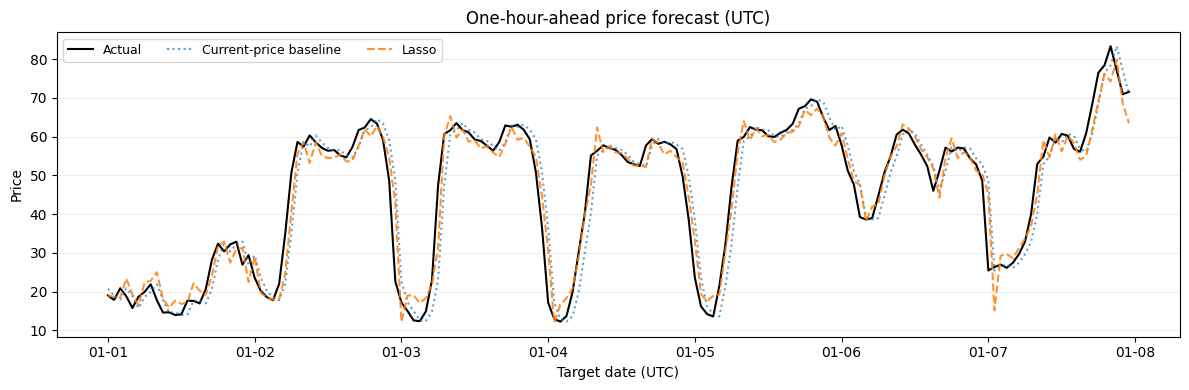

In [20]:
validation_results = pd.DataFrame(validation_records).set_index("model").sort_values("MAE")
display(validation_results.round(4))
best_name = validation_results.index[0]
print("Selected by validation MAE:", best_name)

train_val = pd.concat([train, val]).sort_index()
final_model = clone(fitted_models[best_name])
final_model.fit(train_val[features], train_val["target"])
final_prediction = final_model.predict(X_test)
baseline_prediction = X_test["price_now"].to_numpy()

test_results = pd.DataFrame({
    "Current-price baseline": metrics(y_test, baseline_prediction),
    best_name: metrics(y_test, final_prediction),
}).T
display(test_results.round(4))

predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Baseline": baseline_prediction,
    "Selected model": final_prediction,
}, index=pd.DatetimeIndex(test["target_time"], name="target_time"))
prediction_week = predictions.loc["2018-01-01":"2018-01-07"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(prediction_week.index, prediction_week["Actual"], color="black", label="Actual")
ax.plot(prediction_week.index, prediction_week["Baseline"],
        linestyle=":", alpha=0.7, label="Current-price baseline")
ax.plot(prediction_week.index, prediction_week["Selected model"],
        linestyle="--", alpha=0.85, label=best_name)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set(title="One-hour-ahead price forecast (UTC)", xlabel="Target date (UTC)", ylabel="Price")
ax.legend(ncol=3, fontsize=9)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 最后留一份接口速查

```python
model.fit(X_train, y_train)        # 学习参数
prediction = model.predict(X_val) # 预测

model.get_params()               # 读取配置
model.set_params(model__alpha=1) # Pipeline 内改配置，之后需重新 fit
model.named_steps["model"].coef_ # 线性模型学习到的系数
model.score(X_val, y_val)         # 这里的回归模型通常返回 R²
```

1. `get_params()` 获取配置；`coef_` 等属性获取学习结果。
2. `loss`、`criterion`、`alpha` 含义随模型变化，查该模型的接口。
3. 改 metrics 只改变报告；改 scoring 改变选择标准；改受支持的 loss 才改变训练目标。
4. 填补、标准化都放进 Pipeline；时序交叉验证显式用 TimeSeriesSplit。
5. 每个新输入可以使用当时已经发布的最新历史，但最终测试目标不参与训练或调参。

**后续可以练习：** 调整树深观察训练/验证误差；改变 Ridge alpha 看系数变化；
用目标时刻前一天的价格新增特征，再只在验证阶段比较。